# Missing Value Treatment

Most models cannot handle missing values, and the way you fill them changes what the model learns. The right method depends on **why** values are missing, and must be **evaluated**, not assumed.

**After this lesson you can:**

1. Distinguish MCAR, MAR and MNAR and why it matters.
2. Use deletion, simple imputation, group imputation, KNN and iterative imputation.
3. Add missing-value indicators when missingness carries information.
4. Compare methods with a measured imputation error and with model performance.

**Data:** Ames Housing (`Lot_Frontage`) and Adult census income (`workclass`, `occupation`, `native_country`).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

from sklearn.compose import ColumnTransformer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (activates IterativeImputer)
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ames = datasets.ames()
ames["Lot_Frontage"] = ames["Lot_Frontage"].replace(0, np.nan)        # disguised missing values (Lesson 01)
adult = datasets.adult()
print("Lot_Frontage missing:", ames["Lot_Frontage"].isna().sum(), "| Adult missing:", adult.isna().sum()[adult.isna().sum() > 0].to_dict())

Lot_Frontage missing: 490 | Adult missing: {'workclass': 1836, 'occupation': 1843, 'native_country': 583}


## 1. Why Values Are Missing

| Mechanism | Meaning | Example | Consequence |
| :--- | :--- | :--- | :--- |
| **MCAR** (completely at random) | missingness unrelated to anything | a form page was lost | deletion is unbiased (but wastes data) |
| **MAR** (at random, given other columns) | depends on observed columns | frontage is missing more often for some house styles | impute using the other columns |
| **MNAR** (not at random) | depends on the missing value itself | high earners do not report income | no method fixes it fully; flag it and be careful |

The data can show whether missingness depends on **observed** columns; it can never prove MCAR.

In [2]:
miss = ames["Lot_Frontage"].isna()
by_config = ames.groupby("Lot_Config")["Lot_Frontage"].apply(lambda s: s.isna().mean()).sort_values()
print("share of missing Lot_Frontage by lot configuration:\n", by_config.round(3).to_string())

adult_miss = adult["occupation"].isna()
print("\nAdult: income >50K among rows with / without occupation:",
      f"{(adult.loc[adult_miss, 'income'] == '>50K').mean():.1%} vs {(adult.loc[~adult_miss, 'income'] == '>50K').mean():.1%}")
print("age of rows with missing occupation (median):", adult.loc[adult_miss, "age"].median(), "vs", adult.loc[~adult_miss, "age"].median())

share of missing Lot_Frontage by lot configuration:
 Lot_Config
Inside     0.128
Corner     0.204
FR2        0.235
FR3        0.286
CulDSac    0.489

Adult: income >50K among rows with / without occupation: 10.4% vs 24.9%
age of rows with missing occupation (median): 35.0 vs 37.0


Missing frontage is much more common for some lot configurations (not MCAR), and people with a missing occupation earn more than 50K far less often: missingness **carries information** about the target. Dropping these rows or filling them blindly would hide that signal.

## 2. Measure Imputation Error

To compare imputers fairly, hide values that **are known**, impute them, and compare with the truth. The cell masks 20 % of the observed `Lot_Frontage` values at random and measures the error of five methods.

In [3]:
known = ames[ames["Lot_Frontage"].notna()].copy()
rng = np.random.default_rng(RNG)
mask = rng.random(len(known)) < 0.2
truth = known.loc[mask, "Lot_Frontage"]
work = known.copy()
work.loc[mask, "Lot_Frontage"] = np.nan

num_cols = ["Lot_Frontage", "Lot_Area", "Gr_Liv_Area", "Year_Built", "Total_Bsmt_SF", "Garage_Area", "First_Flr_SF"]
estimates = {
    "mean": work["Lot_Frontage"].fillna(work["Lot_Frontage"].mean()),
    "median": work["Lot_Frontage"].fillna(work["Lot_Frontage"].median()),
    "median by neighbourhood": work["Lot_Frontage"].fillna(work.groupby("Neighborhood")["Lot_Frontage"].transform("median")),
    "KNN (k=10, scaled)": pd.Series(KNNImputer(n_neighbors=10).fit_transform(StandardScaler().fit_transform(work[num_cols]))[:, 0]
                                    * work["Lot_Frontage"].std() + work["Lot_Frontage"].mean(), index=work.index),
    "iterative (regression)": pd.Series(IterativeImputer(random_state=RNG, max_iter=10).fit_transform(work[num_cols])[:, 0], index=work.index),
}
errors = pd.Series({k: np.sqrt(((v[mask] - truth) ** 2).mean()) for k, v in estimates.items()}).sort_values()
print("RMSE on hidden values (feet):\n", errors.round(2).to_string())

RMSE on hidden values (feet):
 KNN (k=10, scaled)         17.52
median by neighbourhood    21.12
mean                       25.04
median                     25.04
iterative (regression)     27.61


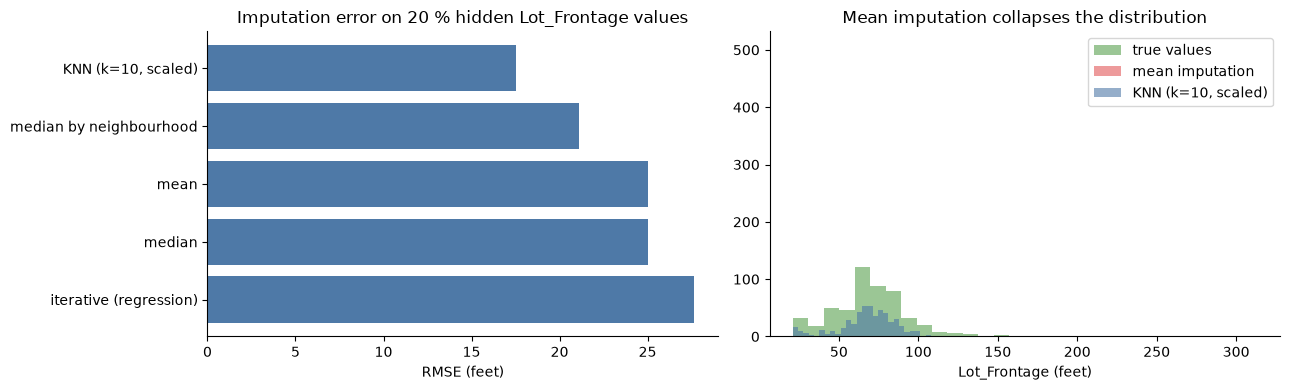

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.barh(errors.index[::-1], errors.values[::-1], color="#4E79A7")
ax1.set(title="Imputation error on 20 % hidden Lot_Frontage values", xlabel="RMSE (feet)")
ax2.hist(truth, bins=30, alpha=0.6, label="true values", color="#59A14F")
ax2.hist(estimates["mean"][mask], bins=30, alpha=0.6, label="mean imputation", color="#E15759")
ax2.hist(estimates[errors.index[0]][mask], bins=30, alpha=0.6, label=errors.index[0], color="#4E79A7")
ax2.set(title="Mean imputation collapses the distribution", xlabel="Lot_Frontage (feet)")
ax2.legend()
plt.tight_layout()
plt.show()

KNN and the neighbourhood median beat the global mean and median. The iterative imputer is **worse** than the mean here: it fits a linear regression of frontage on the other columns, and frontage is not a linear function of them. Using other columns helps only when the method matches the relationship. The mean also puts every hidden value at one point: it **shrinks the variance** and weakens correlations. Note that the error measured here assumes the hidden values are representative of the truly missing ones, which is only approximately true when data is not MCAR.

## 3. Imputation Inside a Model: Adult

For a model, the real test is predictive performance. The cell compares, with 5-fold cross-validation, three strategies for the categorical columns of Adult:

1. drop rows with missing values,
2. impute the most frequent category,
3. treat "missing" as its own category (`fill_value="missing"`), which keeps the signal of missingness.

In [5]:
y = (adult["income"] == ">50K").astype(int)
num = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
cat = ["workclass", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]

def model(cat_imputer):
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", make_pipeline(cat_imputer, OneHotEncoder(handle_unknown="ignore", min_frequency=20)), cat)])
    return make_pipeline(pre, LogisticRegression(max_iter=2000))

results = {}
complete = adult.notna().all(axis=1)
results["drop rows (complete cases)"] = cross_val_score(model(SimpleImputer(strategy="most_frequent")), adult[complete], y[complete],
                                                        cv=5, scoring="roc_auc")
results["most frequent category"] = cross_val_score(model(SimpleImputer(strategy="most_frequent")), adult, y, cv=5, scoring="roc_auc")
results["'missing' as a category"] = cross_val_score(model(SimpleImputer(strategy="constant", fill_value="missing")), adult, y, cv=5,
                                                     scoring="roc_auc")
for k, v in results.items():
    print(f"{k:<28} ROC AUC {v.mean():.4f} ± {v.std():.4f}   rows used: {complete.sum() if 'drop' in k else len(adult):,}")

drop rows (complete cases)   ROC AUC 0.9046 ± 0.0048   rows used: 30,162
most frequent category       ROC AUC 0.9054 ± 0.0042   rows used: 32,561
'missing' as a category      ROC AUC 0.9066 ± 0.0043   rows used: 32,561


The differences are small here because few rows are missing (about 7 %), but the "drop rows" model was trained **and evaluated** only on complete rows: in production, rows with missing values would still arrive and the model would have no rule for them. Keeping "missing" as a category is simple, keeps all rows, and lets the model use the signal of Section 1.

## 4. Missing-Value Indicators for Numeric Columns

For numeric columns, add a binary indicator next to the imputed value (`SimpleImputer(add_indicator=True)`): the model can then learn a separate effect for "was missing".

In [6]:
imp = SimpleImputer(strategy="median", add_indicator=True).set_output(transform="pandas")
out = imp.fit_transform(ames[["Lot_Frontage", "Gr_Liv_Area"]])
print(out.head())
print("\nmedian sale price with / without known frontage:",
      ames.loc[ames["Lot_Frontage"].isna(), "Sale_Price"].median(), "/", ames.loc[ames["Lot_Frontage"].notna(), "Sale_Price"].median())

   Lot_Frontage  Gr_Liv_Area  missingindicator_Lot_Frontage
0         141.0       1656.0                            0.0
1          80.0        896.0                            0.0
2          81.0       1329.0                            0.0
3          93.0       2110.0                            0.0
4          74.0       1629.0                            0.0

median sale price with / without known frontage: 173000.0 / 157500.0


## 5. Rules of Thumb

| Situation | Method |
| :--- | :--- |
| very few missing values, MCAR plausible | drop rows or simple imputation |
| numeric, related to other columns | group median, KNN or iterative imputation |
| categorical | "missing" as its own category |
| missingness itself is informative | add an indicator |
| tree models (gradient boosting) | many handle `NaN` natively (scikit-learn `HistGradientBoosting*`, XGBoost, LightGBM) |
| always | fit the imputer on the **training** data only, inside a pipeline (Lessons 09–10) |

*Insight: Ask why values are missing before you fill them, measure imputers on hidden known values, and keep the information that missingness carries (a category or an indicator). Fit every imputer inside the cross-validation, never on the full dataset.*

## Real-World Use Case or Analogy

Imputation is like **filling gaps in a witness report**: you can use the average of all reports (mean), what similar witnesses said (KNN, group median), or reconstruct it from all other facts (iterative). And sometimes the most important fact is that the witness refused to answer (an indicator).

In credit scoring and healthcare, missing values are often informative: a missing income field or a test that was never ordered says something about the applicant or the patient. Regulators expect the treatment to be documented.